# Phase 5: Validation design

**Goal:** one fixed, fair way to test every model, decided **before** any satellite features or models exist. All of Phases 6 and 7 use it, so their scores can be compared.

**Input:** `data/processed_v2/yield_spatial_v2.gpkg` (1,202 fields, from Phase 2). **Code:** `src/evaluation.py` (the shared test function).
**Output:** `results/phase5/holdout_v2.csv` (final test fields), `results/phase5/folds_v2.csv` (all test splits), reference scores.

**Steps**
1. Measure how far apart fields must be to count as independent (grouping distance).
2. Group nearby fields.
3. Set aside a final test group (hold-out) that no model sees until Phase 8.
4. Make the test splits (folds) on the rest, and check for leakage.
5. Score simple baselines and a ground-data model with every split (the numbers to beat).
6. The comparison test between two models.

**Metrics** (fixed for the thesis): Pearson r (mean over folds, as Cao et al. 2026, and pooled), R², RMSE, MAE, bias, NRMSE (RMSE as % of the mean yield), Spearman ρ, and the MAE on the lowest and highest 10% of yields. Yield in q/acre.

## Step 0: Setup

In [1]:
from pathlib import Path
import sys, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from libpysal.weights import W
from esda.moran import Moran
from catboost import CatBoostRegressor
warnings.filterwarnings("ignore")

here = Path.cwd()
ROOT = here if (here / "data" / "raw").exists() else here.parent
sys.path.insert(0, str(ROOT / "src"))
from evaluation import evaluate, compare, metrics, MeanBaseline, GroupMeanBaseline, SCHEMES

DATA2 = ROOT / "data" / "processed_v2"
OUT = ROOT / "results" / "phase5"; OUT.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "reports" / "figures" / "phase5"; FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

f = gpd.read_file(DATA2 / "yield_spatial_v2.gpkg")            # 1,202 fields (impossible yields already removed)
pts = f.geometry.representative_point(); f["x"], f["y"] = pts.x, pts.y
f = f.set_index("uid", drop=False)
y = f["crop_yield"]

# ground-data features only (no satellite yet): used for the quick model and the reference score
CAT = ["year", "variety", "irrigation", "soil_color_group", "soil_texture_group", "soil_depth_group", "soil_structure_group"]
NUM = ["sowing_doy", "crop_duration", "area_acres", "has_soil_lab"]
X = f[CAT + NUM].copy()
for c in CAT:                                                  # missing values become their own class
    X[c] = X[c].astype(object).where(X[c].notna(), "missing").astype(str)
X["has_soil_lab"] = X["has_soil_lab"].astype(int)
def make_catboost():
    return CatBoostRegressor(iterations=500, depth=6, learning_rate=0.05, loss_function="RMSE",
                             random_seed=SEED, verbose=0, cat_features=CAT,
                             allow_writing_files=False, thread_count=-1)   # no log files: much faster on Windows
print("fields:", len(f), "| per year:", f["year"].value_counts().sort_index().to_dict(), "| features:", len(CAT + NUM))

fields: 1202 | per year: {2022: 55, 2023: 58, 2024: 323, 2025: 766} | features: 11


**Found:** 1,202 fields. The ground-data features are year, variety, irrigation, the four soil description groups, sowing day, crop duration, area and whether soil lab values exist. No location and no satellite data.

## Step 1: Grouping distance

If a test field has a training field right next to it, the model can "copy" the neighbour, and the score looks better than it is. So nearby fields must be kept together. How near is "near"?

1. A quick CatBoost model on the ground data only, tested with random 5-fold, gives an error for every field.
2. Moran's I of those errors, in distance rings (as in Phase 2), shows up to what distance the errors of nearby fields are still alike. That distance is the grouping distance (the "range").
3. Fields closer than the distance, in any year, join the same group. The roadmap compares 200 m, the range and 1 km, and prefers the range unless one group gets bigger than about 10% of the fields.

In [2]:
# (a) quick model on ground data, out-of-fold errors (random 5-fold, design only)
oof = pd.Series(np.nan, index=f.index)
fold = np.random.default_rng(SEED).permutation(np.arange(len(f)) % 5)
for k in range(5):
    m = make_catboost().fit(X[fold != k], y[fold != k]); oof[fold == k] = m.predict(X[fold == k])
f["resid"] = y - oof
print(f"quick model (ground data only): r = {np.corrcoef(y, oof)[0, 1]:.3f}, R2 = {1 - np.sum(f['resid']**2) / np.sum((y - y.mean())**2):.3f}")

# (b) how far do the errors stay alike? Moran's I of the errors in distance rings, per year
BINS = [(0, 250), (250, 500), (500, 1000), (1000, 1500), (1500, 2000), (2000, 3000), (3000, 5000)]
def ring_moran(g, lo, hi):
    xy, r = g[["x", "y"]].to_numpy(), g["resid"].to_numpy(); t = cKDTree(xy)
    o, i = t.query_ball_point(xy, hi), t.query_ball_point(xy, lo)
    nb = {k: sorted(set(o[k]) - set(i[k]) - {k}) for k in range(len(xy))}; keep = [k for k in nb if nb[k]]
    pos = {k: n for n, k in enumerate(keep)}
    w = W({pos[k]: [pos[j] for j in nb[k] if j in pos] for k in keep}, silence_warnings=True)
    if w.s0 / 2 < 30: return np.nan, np.nan
    w.transform = "r"; np.random.seed(SEED); mi = Moran(r[keep], w, permutations=999)
    return mi.I, mi.p_sim
rows = []
for yr in [2024, 2025]:                                        # 2022 and 2023 have too few close pairs
    for lo, hi in BINS:
        I, p = ring_moran(f[f["year"] == yr], lo, hi); rows.append({"year": yr, "from_m": lo, "to_m": hi, "moran_I": I, "p": p})
rc = pd.DataFrame(rows); rc.to_csv(OUT / "P5_error_correlogram.csv", index=False)
print(rc.assign(I=lambda t: t["moran_I"].round(2).astype(str) + np.where(t["p"] < 0.05, " *", "")).pivot(index=["from_m", "to_m"], columns="year", values="I").to_string())
def reach(g):
    for _, r in g.sort_values("from_m").iterrows():
        if not (r["p"] < 0.05 and r["moran_I"] > 0): return int(r["from_m"])
    return int(g["to_m"].max())
RANGE = max(reach(g) for _, g in rc.groupby("year"))
print("\nerrors stay alike up to:", {yr: reach(g) for yr, g in rc.groupby("year")}, "m | range used:", RANGE, "m")

# (c) groups: fields closer than D (any year) end up in the same group
xy_all = f[["x", "y"]].to_numpy(); tree = cKDTree(xy_all)
def groups_at(D):
    pr = np.array(list(tree.query_pairs(D)))
    A = coo_matrix((np.ones(len(pr)), (pr[:, 0], pr[:, 1])), shape=(len(f), len(f)))
    return connected_components(A, directed=False)[1]
rows = []
for D in sorted({200, RANGE, 1000}):
    lab = groups_at(D); sz = np.bincount(lab)
    rows.append({"distance_m": D, "groups": len(sz), "largest_group": sz.max(), "largest_%": round(100 * sz.max() / len(f), 1), "single_fields": int((sz == 1).sum())})
gd = pd.DataFrame(rows); gd.to_csv(OUT / "P5_grouping_distance.csv", index=False)
print(gd.to_string(index=False))

quick model (ground data only): r = 0.387, R2 = 0.144


year           2024     2025
from_m to_m                 
0      250   0.46 *   0.16 *
250    500   0.35 *     0.01
500    1000  0.46 *  -0.06 *
1000   1500   -0.01   0.08 *
1500   2000   -0.04     0.03
2000   3000  0.08 *     0.02
3000   5000  0.08 *    -0.02

errors stay alike up to: {2024: 1000, 2025: 250} m | range used: 1000 m
 distance_m  groups  largest_group  largest_%  single_fields
        200     810             11        0.9            588
       1000     142            140       11.6             73


**Found:**
- The quick model reaches r = 0.39 with ground data only.
- **2024:** the errors stay alike up to **1 km** (Moran's I 0.35 to 0.46), and are gone at 1 to 1.5 km. **2025:** only up to **250 m** (0.16).
- So the range is **1 km** (the larger of the two, to be safe).
- At 1 km there are 142 groups; the largest has 140 fields (**11.6%**), a little above the 10% guide. At 200 m the groups are tiny (largest 0.9%), but 2024 errors are still alike up to 1 km, so 200 m would leak.

## Step 2: Groups

**Decision: 1 km.** Leakage between neighbours (at 200 m) is a bigger problem than one group being slightly over 10% (11.6%). With 5 folds, each fold holds about 20% of the fields, so a group of 11.6% still fits in one fold.

In [3]:
GROUP_DIST = 1000                                             # decision, see the Found line
f["group"] = groups_at(GROUP_DIST)
sizes = f["group"].value_counts()
print(f"groups at {GROUP_DIST} m: {len(sizes)} | largest {sizes.max()} fields ({100 * sizes.max() / len(f):.1f}%)")

groups at 1000 m: 142 | largest 140 fields (11.6%)


## Step 3: Final test group (hold-out)

About **15% of the fields**, taken as **whole 1 km groups** (so no hold-out field has a close neighbour in the rest), and **never used** until the final test in Phase 8. Groups bigger than 5% of all fields cannot be picked, so the hold-out is not one single area.

The draw is repeated 2,000 times with different random orders, and the most balanced draw is kept, judged by:
- the share held out in **every year** and **every taluka** (each should be near 15%),
- the **yield distribution** (Kolmogorov-Smirnov statistic, smaller = more alike),
- the **variety mix**.

The rule and the seed are fixed, so anyone can repeat it.

In [4]:
# hold out about 15% of the fields as whole groups, never used until the final test (Phase 8)
HOLD = 0.15
eligible = sizes[sizes <= 0.05 * len(f)].index                # no single group may be a big part of the test set
var_all = f["variety"].value_counts(normalize=True)
YEARS = sorted(f["year"].unique())
TALUKAS = [t for t, n in f["taluka"].value_counts().items() if n >= 20]          # Deoni (2 fields) left out of the balance
best = None
for s in range(1, 2001):                                      # try 2,000 random draws, keep the most balanced one
    order = np.random.default_rng(s).permutation(eligible); picked, n = [], 0
    for g in order:
        if n >= HOLD * len(f): break
        picked.append(g); n += sizes[g]
    h = f["group"].isin(picked)
    year_dev = max(abs(h[f["year"] == yr].mean() - HOLD) for yr in YEARS)          # every year near 15%
    tal_dev = max(abs(h[f["taluka"] == t].mean() - HOLD) for t in TALUKAS)          # every taluka near 15%
    ks = stats.ks_2samp(y[h], y[~h]).statistic                                       # same yield distribution
    var_gap = 0.5 * (f.loc[h, "variety"].value_counts(normalize=True).reindex(var_all.index, fill_value=0) - var_all).abs().sum()
    score = year_dev + tal_dev + ks + var_gap
    if best is None or score < best[0]: best = (score, s, h.copy(), year_dev, ks, var_gap)
_, HOLD_SEED, f["holdout"], yd, ks, vg = best
h = f["holdout"]
print(f"hold-out: draw {HOLD_SEED} of 2,000 | {h.sum()} fields ({100 * h.mean():.1f}%) in {f.loc[h, 'group'].nunique()} groups")
print("share held out per year:", {int(yr): f"{100 * h[f['year'] == yr].mean():.1f}%" for yr in YEARS})
print("share held out per taluka:", {t: f"{100 * h[f['taluka'] == t].mean():.1f}%" for t in TALUKAS})
print(f"yield: hold-out mean {y[h].mean():.2f}, median {y[h].median()} | rest mean {y[~h].mean():.2f}, median {y[~h].median()} | KS = {ks:.3f}, p = {stats.ks_2samp(y[h], y[~h]).pvalue:.2f}")
print(f"variety mix difference: {100 * vg:.1f}%")
print("Phase 1B groups in hold-out:", f.loc[h, "yield_group"].value_counts().to_dict())
f.loc[h, ["uid", "year", "taluka", "group"]].to_csv(OUT / "holdout_v2.csv", index=False)

hold-out: draw 875 of 2,000 | 183 fields (15.2%) in 37 groups
share held out per year: {2022: '18.2%', 2023: '10.3%', 2024: '18.9%', 2025: '13.8%'}
share held out per taluka: {'Latur': '22.8%', 'Ausa': '5.0%', 'Nilanga': '6.9%', 'Chakur': '26.2%', 'Renapur': '17.1%', 'Shirur-Anantpal': '7.0%'}
yield: hold-out mean 8.43, median 8.5 | rest mean 8.66, median 8.2 | KS = 0.046, p = 0.88
variety mix difference: 9.0%
Phase 1B groups in hold-out: {'clean': 172, 'weak': 9, 'strong': 2}


**Found:**
- **183 fields (15.2%)** in 37 groups.
- Per year: 18.2% (2022), 10.3% (2023), 18.9% (2024), 13.8% (2025).
- Per taluka: 5% (Ausa) to 26% (Chakur). Whole 1 km groups are large, so the taluka balance cannot be perfect.
- **Yield distribution is the same** as in the rest: mean 8.43 vs 8.66, KS = 0.046, p = 0.88.
- Variety mix differs by 9%. 2 strong outliers and 9 weak ones from Phase 1B are in the hold-out, about the same share as in the data.
- The list is saved in `holdout_v2.csv`. **Do not look at these fields' results until Phase 8.**

## Step 4: Test splits on the development fields

The other **1,019 fields** are the development set. Every model is tested with all of these splits:

| Split | What it tests | Role | Cao et al. 2026 |
|---|---|---|---|
| **Random 5-fold** (5 repeats) | nothing realistic: neighbours leak | reference only, shows optimism | their "random" (r = 0.90) |
| **Spatial group 5-fold** (5 repeats) | new fields, no close neighbour | **main score** | |
| **10 km blocks, 5-fold** (5 repeats) | new areas | check | |
| **Leave one year out** (4 folds) | a new season | time transfer | their leave-one-year-out (r = 0.86) |
| **Leave one taluka out** (6 folds) | a new region | space transfer | their leave-one-province-out (r = 0.52) |

Groups and blocks are put into folds of similar size. Deoni (2 fields) is never a test fold; its fields stay in training.

**Leakage check:** for each split, the share of test fields that have a training field within 500 m.

In [5]:
dev = f[~f["holdout"]].copy()
def balanced_folds(labels, k, seed):
    """Put whole labels (groups or blocks) into k folds of similar size, in a random order."""
    cnt = labels.value_counts(); order = np.random.default_rng(seed).permutation(cnt.index)
    load, assign = np.zeros(k), {}
    for g in order:
        j = int(np.argmin(load)); assign[g] = j; load[j] += cnt[g]
    return labels.map(assign)

BLOCK = 10000                                                 # 10 km grid blocks: whole new areas
dev["block"] = (np.floor(dev["x"] / BLOCK).astype(int).astype(str) + "_" + np.floor(dev["y"] / BLOCK).astype(int).astype(str))
folds = pd.DataFrame(index=dev.index)
for s in range(1, 6):
    folds[f"random_s{s}"] = np.random.default_rng(s).permutation(np.arange(len(dev)) % 5)
    folds[f"group_s{s}"] = balanced_folds(dev["group"], 5, s)
    folds[f"block_s{s}"] = balanced_folds(dev["block"], 5, s)
folds["loyo"] = dev["year"]
folds["loto"] = dev["taluka"]
out = f[["uid", "year", "taluka", "group", "holdout"]].join(dev[["block"]]).join(folds)
out.to_csv(OUT / "folds_v2.csv", index=False)
print("development fields:", len(dev), "| groups:", dev["group"].nunique(), "| 10 km blocks:", dev["block"].nunique())
size = lambda c: folds[c].value_counts().sort_index().tolist()
print("fold sizes, group_s1:", size("group_s1"), "| block_s1:", size("block_s1"), "| random_s1:", size("random_s1"))
print("leave-one-year-out:", size("loyo"), "| leave-one-taluka-out:", folds["loto"].value_counts().to_dict())

# leakage check: share of test fields with a training field closer than 500 m, per scheme (first seed)
xy = dev[["x", "y"]].to_numpy(); tr = cKDTree(xy); near = tr.query_ball_point(xy, 500)
rows = []
for c in ["random_s1", "group_s1", "block_s1", "loyo", "loto"]:
    lab = folds[c].to_numpy()
    rows.append({"scheme": c, "test_fields_with_training_field_within_500m_%": round(100 * np.mean([any(lab[j] != lab[i] for j in near[i] if j != i) for i in range(len(xy))]), 1)})
leak = pd.DataFrame(rows); leak.to_csv(OUT / "P5_leakage_check.csv", index=False)
print(leak.to_string(index=False))

development fields: 1019 | groups: 105 | 10 km blocks: 36
fold sizes, group_s1: [216, 264, 207, 166, 166] | block_s1: [215, 201, 192, 207, 204] | random_s1: [204, 204, 204, 204, 203]
leave-one-year-out: [45, 52, 262, 660] | leave-one-taluka-out: {'Latur': 325, 'Ausa': 247, 'Nilanga': 162, 'Renapur': 107, 'Chakur': 96, 'Shirur-Anantpal': 80, 'Deoni': 2}
   scheme  test_fields_with_training_field_within_500m_%
random_s1                                           80.2
 group_s1                                            0.0
 block_s1                                            8.5
     loyo                                           55.4
     loto                                            1.7


**Found:**
- **Random split: 80% of test fields** have a training field within 500 m, so it leaks heavily (as expected).
- **Spatial groups: 0%**, no leakage. This is why it is the main score.
- 10 km blocks: 8.5% (only at block borders). Leave one taluka out: 1.7% (at taluka borders).
- **Leave one year out: 55%.** The same or nearby plots appear in other years (160 repeated plots). So this split tests a new season, but not new places.
- Fold sizes of the group split are uneven (166 to 264), because of the large 140-field group.
- Leave one year out is very uneven: 2022 and 2023 give only 45 and 52 test fields, so their scores will be unstable.

## Step 5: Reference scores (no satellite data yet)

Every later model must beat these, **on the same folds**:
- **Overall mean:** predicts the training mean for everyone.
- **Year × variety mean:** predicts the training mean of the same year and variety. In leave one year out the year is unknown, so it falls back to the overall mean.
- **CatBoost on ground data only:** what management information alone can do.

r is the mean over folds (as Cao et al.) ± SD; r pooled is one r over all test predictions. A model that always predicts the same number has no r (shown as NaN).

In [6]:
Xd, yd, fd = X.loc[dev.index], y.loc[dev.index], folds
runs = {"overall mean": lambda: MeanBaseline(),
        "year x variety mean": lambda: GroupMeanBaseline(),
        "CatBoost, ground data only": make_catboost}
per_fold, summary = {}, []
import time
for name, mk in runs.items():
    t0 = time.time()
    pf, sm, _ = evaluate(mk, Xd, yd, fd)
    print(f"{name}: {len(pf)} tests done in {time.time() - t0:.0f} s")
    per_fold[name] = pf; summary.append(sm.assign(model=name))
    pf.assign(model=name).to_csv(OUT / f"P5_perfold_{name.replace(' ', '_').replace(',', '')}.csv", index=False)
summary = pd.concat(summary)
summary.to_csv(OUT / "P5_reference_scores.csv", index=False)
cols = ["model", "scheme", "folds", "r_mean", "r_sd", "r_pooled", "R2_mean", "RMSE_q_acre_mean", "MAE_q_acre_mean", "NRMSE_pct_mean"]
print(summary[cols].round(3).to_string(index=False))

overall mean: 85 tests done in 0 s


year x variety mean: 85 tests done in 1 s


CatBoost, ground data only: 85 tests done in 108 s
                     model scheme  folds  r_mean  r_sd  r_pooled  R2_mean  RMSE_q_acre_mean  MAE_q_acre_mean  NRMSE_pct_mean
              overall mean random     25     NaN   NaN    -0.052   -0.006             3.139            2.008          36.180
              overall mean  group     25     NaN   NaN    -0.126   -0.035             3.103            2.022          35.652
              overall mean  block     25     NaN   NaN    -0.128   -0.038             3.048            2.021          34.981
              overall mean   loyo      4     NaN   NaN    -0.291   -0.214             3.350            2.315          37.607
              overall mean   loto      6     NaN   NaN    -0.098   -0.035             2.888            1.920          33.934
       year x variety mean random     25   0.330 0.058     0.319    0.090             2.981            1.922          34.361
       year x variety mean  group     25   0.307 0.070     0.275    0.028 

**Found (main split, spatial groups):**
- Overall mean: R² = −0.04, RMSE = 3.10 q/acre (no skill, as expected).
- Year × variety mean: r = 0.31, R² = 0.03, RMSE = 2.99 q/acre.
- CatBoost on ground data: **r = 0.36 ± 0.07**, R² = 0.06, RMSE = 2.96 q/acre.
- **Random split looks better** (CatBoost r = 0.39) than the spatial split (0.36), the effect of leakage.
- **Leave one year out is the hardest:** CatBoost r = 0.10, R² = −0.71. Ground data cannot predict a new season; this is where satellite and weather data must help.
- **Leave one taluka out:** r = 0.35.
- NRMSE is about 33 to 36% everywhere, compared with 8.9 to 19% in Cao et al. Field yields are much noisier than county averages (Phase 1B rounding, Phase 2 nugget).

## Step 6: Comparison test

To say model A is better than model B, both are tested on the same folds, and the fold-by-fold differences are tested with the **Wilcoxon signed-rank test** and the **corrected resampled t-test** (Nadeau and Bengio 2003), which accounts for the folds sharing training data. A difference smaller than the fold-to-fold spread is not a real difference.

CatBoost vs year x variety mean, spatial group 5-fold, RMSE: {'metric': 'RMSE_q_acre', 'scheme': 'group', 'folds': 25, 'mean_diff_A_minus_B': np.float64(-0.0388), 'wilcoxon_p': np.float64(0.0667), 'corrected_t': np.float64(-0.5822), 'corrected_t_p': np.float64(0.5659)}


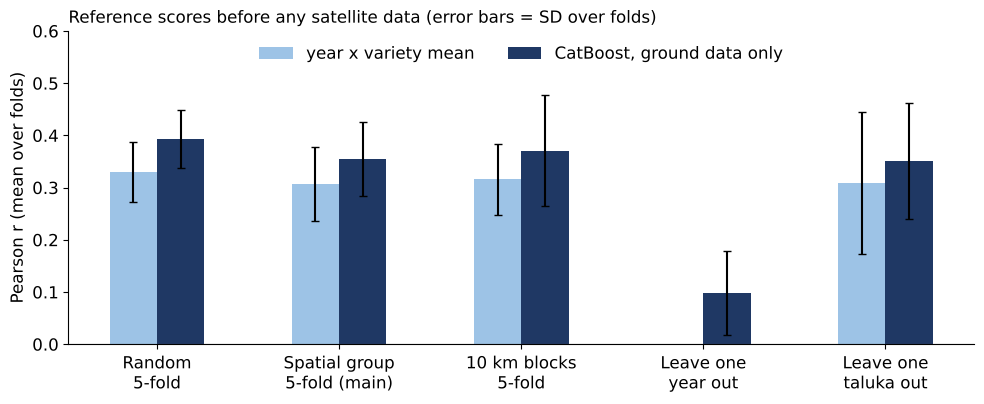

In [7]:
c = compare(per_fold["CatBoost, ground data only"], per_fold["year x variety mean"], metric="RMSE_q_acre", scheme="group")
print("CatBoost vs year x variety mean, spatial group 5-fold, RMSE:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in c.items()})

# figure: r by scheme for the three reference models
sch = ["random", "group", "block", "loyo", "loto"]
lab = {"random": "Random\n5-fold", "group": "Spatial group\n5-fold (main)", "block": "10 km blocks\n5-fold", "loyo": "Leave one\nyear out", "loto": "Leave one\ntaluka out"}
fig, ax = plt.subplots(figsize=(10, 4.2)); w = 0.26
for i, (name, col) in enumerate([("year x variety mean", "#9DC3E6"), ("CatBoost, ground data only", "#1F3864")]):
    s = summary[summary["model"] == name].set_index("scheme").reindex(sch)
    ax.bar(np.arange(len(sch)) + (i - 0.5) * w, s["r_mean"], w, yerr=s["r_sd"], color=col, label=name, capsize=3)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(range(len(sch)), [lab[s] for s in sch]); ax.set_ylabel("Pearson r (mean over folds)")
ax.set_title("Reference scores before any satellite data (error bars = SD over folds)", loc="left", fontsize=12)
ax.set_ylim(0, 0.6); ax.legend(frameon=False, ncol=2, loc="upper center")
fig.tight_layout(); fig.savefig(FIG / "P5_reference_r.png", dpi=300, facecolor="white"); plt.show()

**Found:**
- CatBoost on ground data has a 0.04 q/acre lower RMSE than the year × variety mean, but this is **not significant** (Wilcoxon p = 0.07, corrected t-test p = 0.57). Ground data alone adds almost nothing beyond knowing the year and variety.
- So the reference to beat is **r ≈ 0.31 to 0.36 and RMSE ≈ 2.96 q/acre** on the spatial group split.

## Summary

| Item | Decision |
|---|---|
| Grouping distance | 1 km (errors alike up to 1 km in 2024, 250 m in 2025); 142 groups, largest 11.6% |
| Hold-out | 183 fields (15.2%), 37 whole groups, same yield distribution (KS p = 0.88); untouched until Phase 8 |
| Main split | spatial group 5-fold, 5 repeats (25 folds), no leakage within 500 m |
| Other splits | random 5-fold (optimism), 10 km blocks, leave one year out, leave one taluka out |
| Metrics | r (fold mean and pooled), R², RMSE, MAE, bias, NRMSE, Spearman ρ, MAE of lowest and highest 10% |
| Baselines | overall mean; year × variety mean; CatBoost on ground data (r = 0.36, RMSE 2.96 q/acre) |
| Comparison test | Wilcoxon signed-rank and corrected resampled t-test on the same folds |

**Limits**
- The grouping distance came from a ground-data model. It is checked again in Phase 6 with the satellite model's errors.
- Fields that end up with too few pixels in Phase 4 are dropped from both sets; the drop is reported.
- Leave one year out has only 4 folds, two of them small.

**References**
- Cao, B. et al. (2026). Physics-guided deep learning for crop yield estimation. European Journal of Agronomy, 172, 127850.
- Nadeau, C. and Bengio, Y. (2003). Inference for the generalization error. Machine Learning, 52(3), 239-281.
- Roberts, D.R. et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. Ecography, 40(8), 913-929.